# California Housing Value Prediction

**Junior Jele — guided learning project**

Predict the recorded median house value of a census block group using eight numerical features.
The dataset describes California in 1990. It does not describe individual houses or current prices.

Run all cells from top to bottom in a Python environment with the dependencies in `requirements.txt`.
The first run downloads the dataset through scikit-learn; internet access is required unless cached.

We reserve 20% of the data for a final test, explore only the training portion after a brief initial
schema preview, compare models using the same five training-only folds, and select a random forest.
The test set is then evaluated for reporting and error analysis, without further model changes.

Dataset: [scikit-learn California Housing](https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset).
This notebook was developed through guided Python and machine learning practice with AI assistance.


## 1. Load Data

Each row is a census area. The target `MedHouseVal` is in $100,000 units.


In [1]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (20640, 9)
Out[1]: 
   MedInc  HouseAge  AveRooms  ...  Latitude  Longitude  MedHouseVal
0  8.3252      41.0  6.984127  ...     37.88    -122.23        4.526
1  8.3014      21.0  6.238137  ...     37.86    -122.22        3.585
2  7.2574      52.0  8.288136  ...     37.85    -122.24        3.521
3  5.6431      52.0  5.817352  ...     37.85    -122.25        3.413
4  3.8462      52.0  6.281853  ...     37.85    -122.25        3.422

[5 rows x 9 columns]


## 2. Reserve the Test Set

Use a repeatable random split: 16,512 training areas and 4,128 test areas.


In [2]:
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)
print("Training data:", train_df.shape)
print("Test data:", test_df.shape)

Training data: (16512, 9)
Test data: (4128, 9)


## 3. Explore Training Data

Check recorded values, summary statistics, distributions, and relationships. A weak linear correlation does not rule out nonlinear predictive value.


In [3]:
train_df.info()
print("\nMissing values per column:")
print(train_df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 16512 entries, 14196 to 15795
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       16512 non-null  float64
 1   HouseAge     16512 non-null  float64
 2   AveRooms     16512 non-null  float64
 3   AveBedrms    16512 non-null  float64
 4   Population   16512 non-null  float64
 5   AveOccup     16512 non-null  float64
 6   Latitude     16512 non-null  float64
 7   Longitude    16512 non-null  float64
 8   MedHouseVal  16512 non-null  float64
dtypes: float64(9)
memory usage: 1.3 MB

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [4]:
train_df.describe().round(2)

Out[4]: 
         MedInc  HouseAge  AveRooms  ...  Latitude  Longitude  MedHouseVal
count  16512.00  16512.00  16512.00  ...  16512.00   16512.00     16512.00
mean       3.88     28.61      5.44  ...     35.64    -119.58         2.07
std        1.90     12.60      2.39  ...      2.14       2.01         1.16
min        0.50      1.00      0.89  ...     32.55    -124.35         0.15
25%        2.57     18.00      4.45  ...     33.93    -121.81         1.20
50%        3.55     29.00      5.24  ...     34.26    -118.51         1.80
75%        4.77     37.00      6.06  ...     37.72    -118.01         2.65
max       15.00     52.00    141.91  ...     41.95    -114.31         5.00

[8 rows x 9 columns]


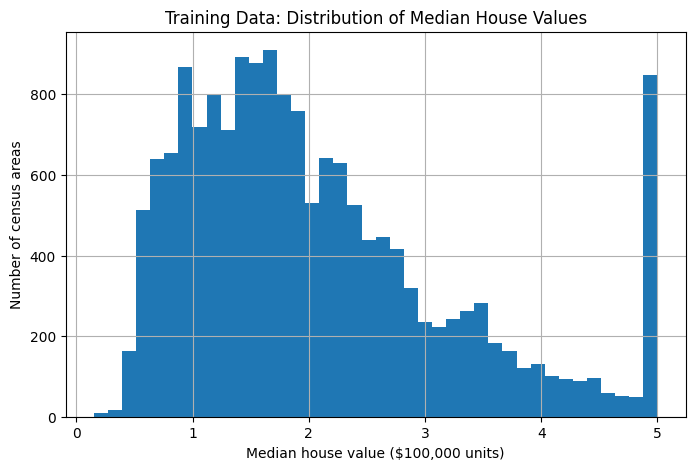

In [5]:
import matplotlib.pyplot as plt

train_df["MedHouseVal"].hist(bins=40, figsize=(8, 5))

plt.xlabel("Median house value ($100,000 units)")
plt.ylabel("Number of census areas")
plt.title("Training Data: Distribution of Median House Values")
plt.show()

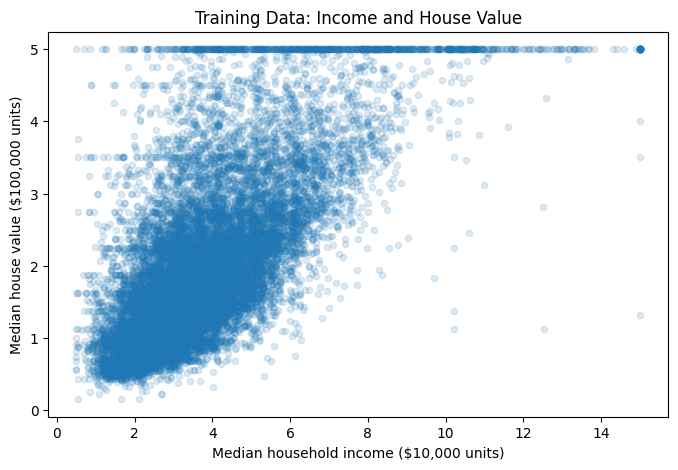

In [6]:
train_df.plot.scatter(
    x="MedInc",
    y="MedHouseVal",
    alpha=0.15,
    figsize=(8, 5)
)

plt.xlabel("Median household income ($10,000 units)")
plt.ylabel("Median house value ($100,000 units)")
plt.title("Training Data: Income and House Value")
plt.show()

In [7]:
correlations = train_df.corr()["MedHouseVal"]

print(
    correlations
    .drop("MedHouseVal")
    .sort_values(ascending=False)
    .round(3)
)

MedInc        0.691
AveRooms      0.158
HouseAge      0.104
AveOccup     -0.022
Population   -0.026
Longitude    -0.046
AveBedrms    -0.051
Latitude     -0.143
Name: MedHouseVal, dtype: float64


## 4. Separate Features and Target


In [8]:
X_train = train_df.drop(columns=["MedHouseVal"])
y_train = train_df["MedHouseVal"].copy()

print("Input features:", X_train.shape)
print("Target:", y_train.shape)

Input features: (16512, 8)
Target: (16512,)


## 5. Mean-Prediction Baseline

MAE averages absolute errors. The fold training mean is fitted independently inside each round. A median baseline could also be considered because the median minimizes constant-prediction absolute error.


In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

baseline = DummyRegressor(strategy="mean")

baseline_scores = cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

baseline_mae = -baseline_scores.mean()

print(f"Baseline CV MAE: ${baseline_mae * 100_000:,.0f}")

Baseline CV MAE: $91,391


## 6. Linear Regression

The scaler is inside the pipeline and is refitted in each training fold. Ordinary least squares minimizes squared error; MAE is our common validation metric. Scaling is not required for the predictions of unregularized least squares, but demonstrates safe pipeline construction.


In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear_scores = cross_val_score(
    linear_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

linear_mae = -linear_scores.mean()

print(f"Baseline CV MAE: ${baseline_mae * 100_000:,.0f}")
print(f"Linear regression CV MAE: ${linear_mae * 100_000:,.0f}")
print(f"MAE reduction: {(1 - linear_mae / baseline_mae):.1%}")

Baseline CV MAE: $91,391
Linear regression CV MAE: $52,906
MAE reduction: 42.1%


## 7. Decision Tree Regression

Use a depth-5 tree. Leaves predict training-group mean target values.


In [11]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

tree_scores = cross_val_score(
    tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

tree_mae = -tree_scores.mean()

print(f"Linear regression CV MAE: ${linear_mae * 100_000:,.0f}")
print(f"Decision tree CV MAE: ${tree_mae * 100_000:,.0f}")

Linear regression CV MAE: $52,906
Decision tree CV MAE: $52,658


## 8. Random Forest Regression

Use 100 bootstrap-sampled trees with unrestricted depth. Predictions average the trees. These settings differ from the shallow single tree, so this is not a controlled comparison of averaging alone.


In [12]:
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

forest_scores = cross_val_score(
    forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

forest_mae = -forest_scores.mean()

print(f"Baseline CV MAE: ${baseline_mae * 100_000:,.0f}")
print(f"Linear regression CV MAE: ${linear_mae * 100_000:,.0f}")
print(f"Decision tree CV MAE: ${tree_mae * 100_000:,.0f}")
print(f"Random forest CV MAE: ${forest_mae * 100_000:,.0f}")

Baseline CV MAE: $91,391
Linear regression CV MAE: $52,906
Decision tree CV MAE: $52,658
Random forest CV MAE: $33,504


## 9. Compare All Five Folds

Lower dollar MAE is better. Select the current random forest based on validation results, before viewing test performance.


In [13]:
fold_errors = pd.DataFrame({
    "Baseline": -baseline_scores * 100_000,
    "Linear regression": -linear_scores * 100_000,
    "Decision tree": -tree_scores * 100_000,
    "Random forest": -forest_scores * 100_000
})

fold_errors.index = [
    "Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"
]

display(fold_errors.round(0))

,Baseline,Linear regression,Decision tree,Random forest
Fold 1,92577.0,54071.0,54100.0,34394.0
Fold 2,91154.0,52879.0,51988.0,32956.0
Fold 3,91421.0,51274.0,52838.0,33151.0
Fold 4,92156.0,53512.0,52592.0,33741.0
Fold 5,89649.0,52793.0,51774.0,33277.0


## 10. Fit the Selected Model and Evaluate Once

Fit a fresh copy on all training areas. Report test MAE and RMSE; RMSE places greater weight on large errors. Keep this model fixed after inspecting test outcomes.


In [14]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error

final_model = clone(forest_model)
final_model.fit(X_train, y_train)

X_test = test_df.drop(columns=["MedHouseVal"])
y_test = test_df["MedHouseVal"].copy()

test_predictions = final_model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = mean_squared_error(y_test, test_predictions) ** 0.5

print(f"Random forest CV MAE: ${forest_mae * 100_000:,.0f}")
print(f"Final test MAE: ${test_mae * 100_000:,.0f}")
print(f"Final test RMSE: ${test_rmse * 100_000:,.0f}")

Random forest CV MAE: $33,504
Final test MAE: $32,754
Final test RMSE: $50,534


## 11. Inspect Test Errors

Points above the diagonal are overpredictions. Points below it are underpredictions. The vertical band near $500,000 reflects the capped recorded target.


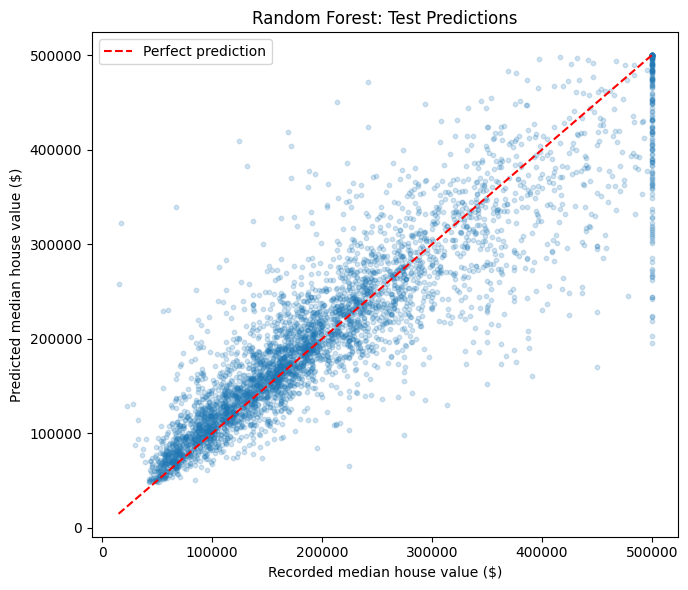

In [15]:
actual_dollars = y_test * 100_000
predicted_dollars = test_predictions * 100_000

plt.figure(figsize=(7, 6))

plt.scatter(
    actual_dollars,
    predicted_dollars,
    alpha=0.2,
    s=10
)

limits = [
    min(actual_dollars.min(), predicted_dollars.min()),
    max(actual_dollars.max(), predicted_dollars.max())
]

plt.plot(limits, limits, "r--", label="Perfect prediction")
plt.xlabel("Recorded median house value ($)")
plt.ylabel("Predicted median house value ($)")
plt.title("Random Forest: Test Predictions")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
errors = pd.DataFrame({
    "Recorded value ($)": actual_dollars,
    "Prediction ($)": predicted_dollars
})

errors["Error ($)"] = (
    errors["Prediction ($)"] - errors["Recorded value ($)"]
)

errors["Absolute error ($)"] = errors["Error ($)"].abs()

display(errors.head(10).round(0))

,Recorded value ($),Prediction ($),Error ($),Absolute error ($)
20046,47700.0,50950.0,3250.0,3250.0
3024,45800.0,74161.0,28361.0,28361.0
15663,500001.0,492326.0,-7675.0,7675.0
20484,218600.0,252961.0,34361.0,34361.0
9814,278000.0,227369.0,-50631.0,50631.0
13311,158700.0,164692.0,5992.0,5992.0
7113,198200.0,237605.0,39405.0,39405.0
7668,157500.0,166932.0,9432.0,9432.0
18246,340000.0,277297.0,-62703.0,62703.0
5723,446600.0,491346.0,44746.0,44746.0


## 12. Training Feature Importance

These normalized importances describe the reduction in training squared-error impurity. They do not show direction or causation, can favor features with more split choices, and can be shared by correlated inputs.


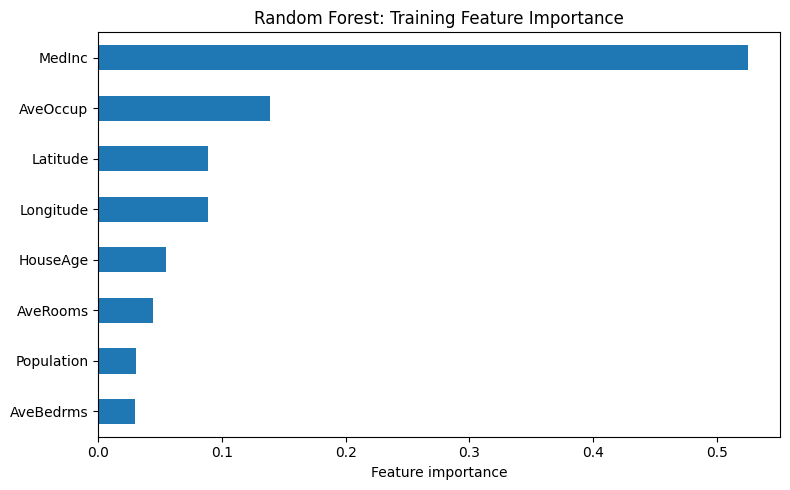

In [17]:
importance = pd.Series(
    final_model.feature_importances_,
    index=X_train.columns
).sort_values()

importance.plot.barh(figsize=(8, 5))

plt.xlabel("Feature importance")
plt.title("Random Forest: Training Feature Importance")
plt.tight_layout()
plt.show()

## Conclusions

We predicted median house values for California census areas using
eight numerical features.

A mean-prediction baseline, linear regression, a depth-5 decision
tree, and a 100-tree random forest were compared using the same
five cross-validation folds.

| Model | Mean CV MAE |
|---|---:|
| Mean baseline | $91,391 |
| Linear regression | $52,906 |
| Decision tree | $52,658 |
| Random forest | $33,504 |

Random forest had the lowest MAE in every fold and was selected
before evaluating the reserved test set.

After fitting on all 16,512 training areas, it achieved:

- Test MAE: $32,754
- Test RMSE: $50,534
- Test areas: 4,128

Median income had the largest training feature importance.
Low individual linear correlation did not necessarily imply low
usefulness to the forest.

## Limitations

- The data describe census areas in 1990, not individual houses
  or current housing prices.
- Recorded target values are capped near $500,000.
- Random splits can place neighboring areas in training and test
  sets. These results do not establish performance in entirely
  new geographic regions.
- Extreme feature values were retained without adjustment.
- Training feature importance is model-specific, can be biased,
  and does not establish causation.
- Only a small set of model configurations was compared.
- Test errors were inspected for interpretation; the selected
  model was not changed afterward.